Load the Data

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../Data/Evaluation_Results.csv")

df.head()

,participant_id,group,background,condition,task_set,quantitative_difference_response,quantitative_difference_correct,temporal_change_response,temporal_change_correct,completion_time_sec,confidence_rating,difficulty_rating,approach_explanation
0,1,1,Engineering,Static,A,71,0,1st Floor Lobby Area,0,245,2,8,I wasn't able to read the graph correctly. And...
1,3,1,Non-Engineering,Static,A,3,0,1st Floor Lobby Area,0,138,5,4,I was confused with the first question on what...
2,1,1,Engineering,Interactive,B,-17,0,4th Floor Study Lounge,0,171,4,6,I asked a better question this time around not...
3,3,1,Non-Engineering,Interactive,B,96,0,1st Floor Sandella Cafe,1,275,5,6,I added 52% and 66% and got 118 then I subtrac...
4,2,2,Engineering,Interactive,A,10,0,2nd Floor CS Study Lounge Quiet,1,223,1,10,I made a wild assumption because I didn't full...


Derive New Attributes

In [3]:
df["accuracy_rate"] = (df["quantitative_difference_correct"] + df["temporal_change_correct"]) / 2
df["total_correct"] = (df["quantitative_difference_correct"] + df["temporal_change_correct"])

Generate Summary Statistics

In [4]:
condition_summary = df.groupby("condition")[[
    "accuracy_rate",
    "completion_time_sec",
    "confidence_rating",
    "difficulty_rating"
]].agg(["mean", "median", "std"])

condition_summary

accuracy_rate                  completion_time_sec         \
                     mean median       std                mean median   
condition                                                               
Interactive      0.500000    0.5  0.426401          159.083333  134.0   
Static           0.708333    1.0  0.396481          112.250000  107.5   

                       confidence_rating                  difficulty_rating  \
                   std              mean median       std              mean   
condition                                                                     
Interactive  80.674946          5.916667    6.0  2.193309          5.333333   
Static       48.891578          6.500000    7.0  1.783765          5.333333   

                              
            median       std  
condition                     
Interactive    5.5  2.309401  
Static         4.5  2.309401

Compare Tasks (Quantitative vs. Temporal)

In [5]:
task_accuracy = pd.DataFrame({
    "Task": [
        "Quantitative Difference",
        "Temporal Change"
    ],
    "Accuracy": [
        df["quantitative_difference_correct"].mean(),
        df["temporal_change_correct"].mean()
    ]
})

task_accuracy

,Task,Accuracy
0,Quantitative Difference,0.625000
1,Temporal Change,0.583333


Participant-Level View

In [6]:
participant_compare = df.pivot(
    index="participant_id",
    columns="condition",
    values=["accuracy_rate", "completion_time_sec"]
)

participant_compare

accuracy_rate        completion_time_sec       
condition        Interactive Static         Interactive Static
participant_id                                                
1                        0.0    0.0               171.0  245.0
2                        0.5    0.5               223.0  105.0
3                        0.5    0.0               275.0  138.0
4                        0.0    1.0                78.0   76.0
5                        0.0    0.5               104.0   62.0
6                        1.0    1.0               290.0  115.0
7                        0.5    1.0                91.0   78.0
8                        1.0    1.0                71.0  130.0
9                        0.5    1.0               245.0  124.0
10                       1.0    1.0               103.0  100.0
11                       0.0    1.0                94.0   64.0
12                       1.0    0.5               164.0  110.0

Condition Accuracy Counts

In [7]:
df.groupby("condition")["accuracy_rate"].value_counts().sort_index()

condition    accuracy_rate
Interactive  0.0              4
             0.5              4
             1.0              4
Static       0.0              2
             0.5              3
             1.0              7
Name: count, dtype: int64

Task-Level Accuracy

In [8]:
df.groupby("condition")[
    [
        "quantitative_difference_correct",
        "temporal_change_correct"
    ]
].mean()

,quantitative_difference_correct,temporal_change_correct
condition,,
Interactive,0.416667,0.583333
Static,0.833333,0.583333


Time Distributions

In [9]:
df.groupby("condition")["completion_time_sec"].describe()

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
Interactive,12.0,159.083333,80.674946,71.0,93.25,134.0,228.5,290.0
Static,12.0,112.250000,48.891578,62.0,77.50,107.5,125.5,245.0


Average Correct Answers by Condition

In [10]:
df.groupby("condition")[
    "total_correct"
].mean()

condition
Interactive    1.000000
Static         1.416667
Name: total_correct, dtype: float64

Visualization 1: Accuracy by Condition

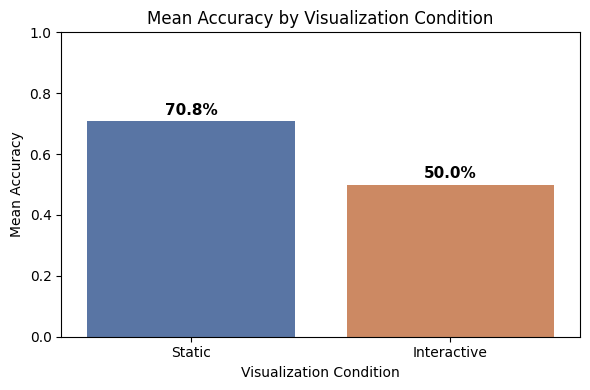

In [11]:
accuracy_summary = (
    df.groupby("condition")["accuracy_rate"]
      .mean()
      .reindex(["Static", "Interactive"])
      .reset_index()
)

plt.figure(figsize=(6, 4))

ax = sns.barplot(
    data=accuracy_summary,
    x="condition",
    y="accuracy_rate",
    hue="condition",
    legend=False,
    palette=["#4C72B0", "#DD8452"]
)

for i, row in accuracy_summary.iterrows():
    ax.text(
        i,
        row["accuracy_rate"] + 0.02,
        f"{row['accuracy_rate']*100:.1f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.ylim(0, 1)
plt.ylabel("Mean Accuracy")
plt.xlabel("Visualization Condition")
plt.title("Mean Accuracy by Visualization Condition")

plt.tight_layout()
plt.show()

Visualization 2: Completion Time by Visualization Condition

/var/folders/jj/x9p4qj9s3dz1rhh61kzc_v000000gn/T/ipykernel_67626/2080915949.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


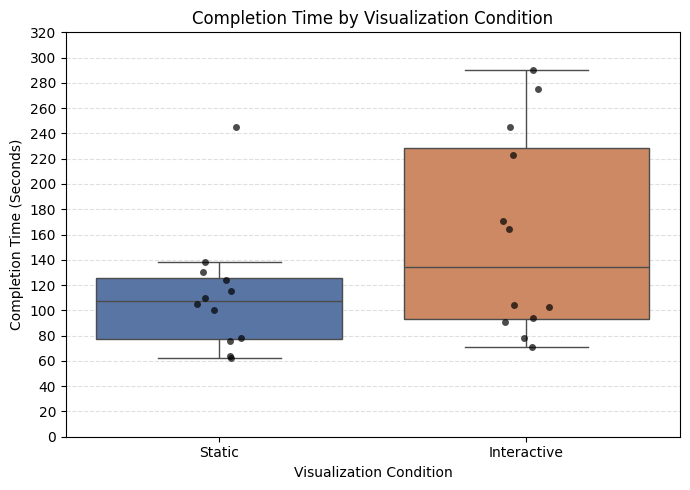

In [12]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="condition",
    y="completion_time_sec",
    palette=["#4C72B0", "#DD8452"],
    showfliers=False
)

sns.stripplot(
    data=df,
    x="condition",
    y="completion_time_sec",
    color="black",
    alpha=0.7,
    jitter=0.08,
    size=5
)

plt.yticks(np.arange(0, 325, 20))

plt.ylabel("Completion Time (Seconds)")
plt.xlabel("Visualization Condition")
plt.title("Completion Time by Visualization Condition")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Visualization 3: Task Accuracy by Task Type and Condition

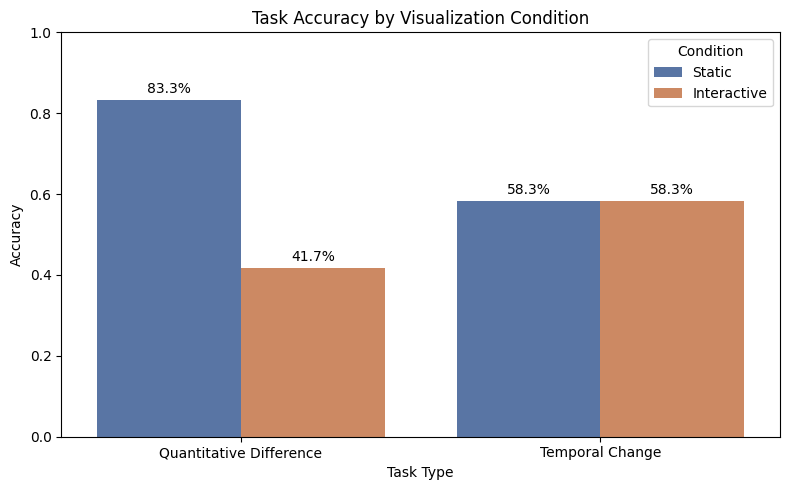

In [13]:
task_accuracy = pd.DataFrame({
    "task": [
        "Quantitative Difference",
        "Quantitative Difference",
        "Temporal Change",
        "Temporal Change"
    ],
    "condition": [
        "Static",
        "Interactive",
        "Static",
        "Interactive"
    ],
    "accuracy": [
        df[df["condition"] == "Static"]["quantitative_difference_correct"].mean(),
        df[df["condition"] == "Interactive"]["quantitative_difference_correct"].mean(),
        df[df["condition"] == "Static"]["temporal_change_correct"].mean(),
        df[df["condition"] == "Interactive"]["temporal_change_correct"].mean()
    ]
})

task_accuracy

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=task_accuracy,
    x="task",
    y="accuracy",
    hue="condition",
    palette=["#4C72B0", "#DD8452"]
)

for container in ax.containers:
    labels = [f"{v * 100:.1f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

plt.ylim(0, 1)

plt.ylabel("Accuracy")
plt.xlabel("Task Type")
plt.title("Task Accuracy by Visualization Condition")

plt.legend(title="Condition")

plt.tight_layout()
plt.show()

Visualization 4: Participant-Level Completion Time Comparison

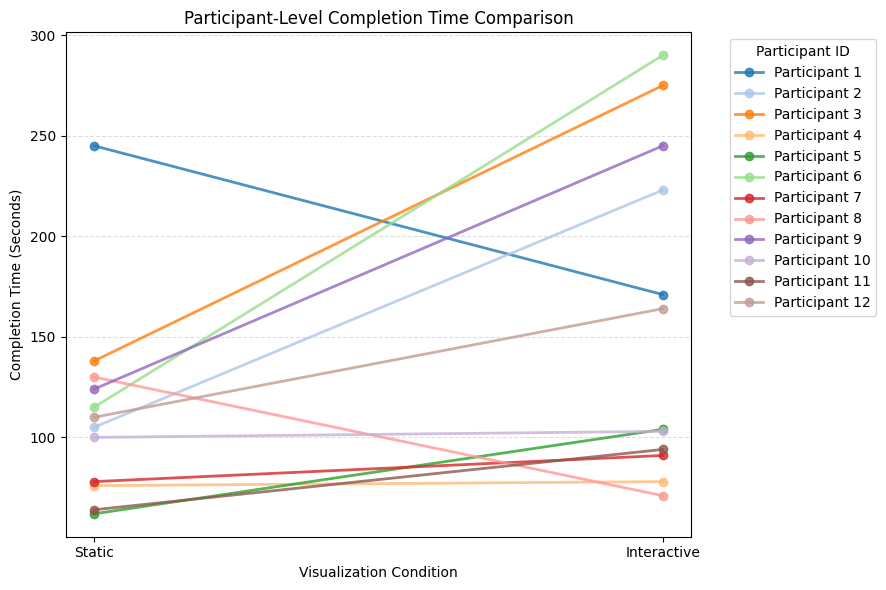

In [14]:
participant_times = df.pivot(
    index="participant_id",
    columns="condition",
    values="completion_time_sec"
)

participant_times

plt.figure(figsize=(9,6))

colors = sns.color_palette("tab20", n_colors=len(participant_times))

for color, participant in zip(colors, participant_times.index):

    plt.plot(
        ["Static", "Interactive"],
        [
            participant_times.loc[participant, "Static"],
            participant_times.loc[participant, "Interactive"]
        ],
        marker="o",
        linewidth=2,
        alpha=0.8,
        color=color,
        label=f"Participant {participant}"
    )

plt.ylabel("Completion Time (Seconds)")
plt.xlabel("Visualization Condition")
plt.title("Participant-Level Completion Time Comparison")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.legend(
    title="Participant ID",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Export Updated Data

In [47]:
df.to_csv(
    "../Data/evaluation_results_cleaned.csv",
    index=False
)

Get Summary Statistics to Support the Boxplot

In [15]:
completion_summary = df.groupby("condition")["completion_time_sec"].agg([
    "min",
    lambda x: x.quantile(0.25),
    "median",
    lambda x: x.quantile(0.75),
    "max",
    "std"
])

completion_summary.columns = [
    "min",
    "q1",
    "median",
    "q3",
    "max",
    "std"
]

completion_summary

,min,q1,median,q3,max,std
condition,,,,,,
Interactive,71,93.25,134.0,228.5,290,80.674946
Static,62,77.50,107.5,125.5,245,48.891578
